# TVA Grid Sensor Placement: starter notebook

In this simplified model, a PMU (phasor measurement unit) at a substation measures that substation and every substation one power line away. PMUs are expensive to install. Your job: find the smallest set of substations that lets TVA's operators see every substation.

In this notebook you will:
1. Draw the IEEE 14-bus test grid and place sensors by hand.
2. Build two classical baselines: a greedy rule and an exact integer program.
3. Write the cost function that QAOA will minimize, with one qubit per substation.
4. Run QAOA on a simulator, first on a 6-substation piece, then on all 14.
5. Run the 6-substation piece on IonQ through qBraid.

**Your 3 TODOs:** the greedy rule, the cost function, and the QAOA cost layer. Everything else is provided and working. A TODO raises `NotImplementedError` until you fill it in.

Words we use: a **bus** is an electrical node in a substation (here, one per substation), a **line** is a power line, and a bus is **seen** when at least one sensor sees it.

> **Before you run anything, pick the kernel.** When this notebook opens, a **Select Kernel** box appears with *Python 3 (ipykernel)* already selected. That's the wrong one: change it to **qBraid-SDK (v0.12.2)**, then click **Select**. Picked the wrong one, or closed the box? Click the kernel name at the top right of the notebook and choose **qBraid-SDK (v0.12.2)**. The first cell checks, and tells you if it's wrong.

In [1]:
# Use the qBraid-SDK (v0.12.2) kernel. This stops with a clear message if another one is picked.
import importlib.util
missing = [m for m in ("qbraid", "matplotlib") if importlib.util.find_spec(m) is None]
if missing:
    raise ImportError("Wrong kernel: this one has no " + " or ".join(missing) + ". Click the kernel name "
                      "at the top right of the notebook, pick qBraid-SDK (v0.12.2), then run this cell again.")

# Qiskit Aer is Qiskit's simulator. It runs right here in your Lab instance: instant, free and noise-free,
# with no job and no credits. The first run installs it (a few seconds), pinned to the version tested here.
try:
    import qiskit_aer  # noqa: F401
except ImportError:
    %pip install -q qiskit-aer==0.18.2

import time
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from scipy.optimize import milp, LinearConstraint, Bounds, minimize

# check.py sits next to this notebook: it loads the grids and checks placements
from check import load_grid, seen_buses, check_placement, brute_force_best, bits_to_buses

sim = AerSimulator()

print("Setup OK: the qBraid kernel and Qiskit Aer are ready. You're good to go.")

Setup OK: the qBraid kernel and Qiskit Aer are ready. You're good to go.


## 1. Load and draw the grid

`grid["buses"]` lists the bus numbers, `grid["lines"]` lists the power lines, and `grid["neighbors"][b]` is the set of buses one line away from bus `b`. Later, qubit `i` stands for bus `grid["buses"][i]`.

`piece` is a 6-substation piece of the same grid, small enough for real quantum hardware.

IEEE 14-bus | 14 buses, 20 lines
IEEE 14-bus, 6-substation piece | buses [2, 3, 5, 6, 10, 11]


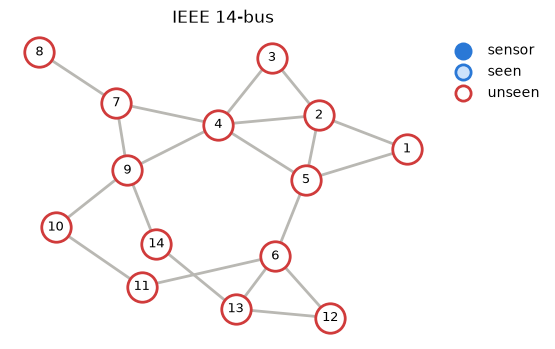

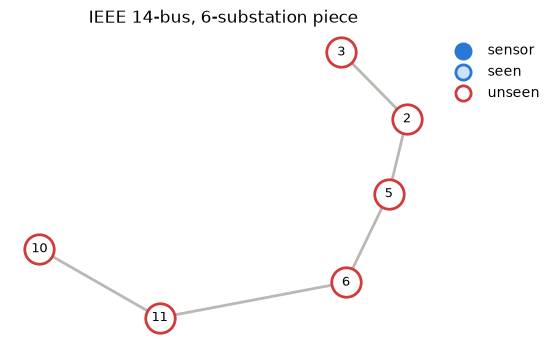

In [2]:
grid = load_grid("data/ieee14.json")
piece = load_grid("data/ieee14_piece6.json")
print(grid["name"], "|", len(grid["buses"]), "buses,", len(grid["lines"]), "lines")
print(piece["name"], "| buses", piece["buses"])


def layout(g):
    # networkx is only used to lay out the drawing; without it, buses go on a circle
    try:
        import networkx as nx
        return nx.kamada_kawai_layout(nx.Graph(g["lines"]))
    except ImportError:
        angle = np.linspace(0, 2 * np.pi, len(g["buses"]), endpoint=False)
        return {b: (np.cos(a), np.sin(a)) for b, a in zip(g["buses"], angle)}


def draw_grid(g, chosen=(), title="", pos=None):
    pos = pos or layout(g)
    seen = seen_buses(g, chosen)
    fig, ax = plt.subplots(figsize=(5.5, 4))
    for a, b in g["lines"]:
        ax.plot(*zip(pos[a], pos[b]), color="#b9b8b3", lw=2, zorder=1)
    for b in g["buses"]:
        face = "#2a78d6" if b in chosen else ("#cde2fb" if b in seen else "white")
        ring = "#2a78d6" if b in seen else "#d03b3b"
        ax.scatter(*pos[b], s=450, c=face, edgecolors=ring, linewidths=2, zorder=2)
        ax.annotate(str(b), pos[b], ha="center", va="center", fontsize=9, zorder=3,
                    color="white" if b in chosen else "black")
    for label, face, ring in [("sensor", "#2a78d6", "#2a78d6"), ("seen", "#cde2fb", "#2a78d6"), ("unseen", "white", "#d03b3b")]:
        ax.scatter([], [], s=120, c=face, edgecolors=ring, linewidths=2, label=label)
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1), frameon=False)
    ax.set_title(title or g["name"])
    ax.margins(0.08)
    ax.axis("off")
    plt.show()


pos14 = layout(grid)              # one layout, so the piece sits where it is in the full grid
draw_grid(grid, pos=pos14)
draw_grid(piece, pos=pos14)

## Milestone 1: place sensors by hand

Look at the drawing of the 14-bus grid. Put bus numbers in `my_guess`, run the cell, and repeat until every bus is seen with as few sensors as you can manage. The checker tells you whether your placement is valid. Try it by hand before you run section 2: its integer program prints the fewest possible.

IEEE 14-bus | rules: see neighbors | sensors at [2, 6, 7, 9]
  VALID with 4 sensors, redundancy 19
  if the sensor at any of [2, 6, 7, 9] fails, some bus goes unseen


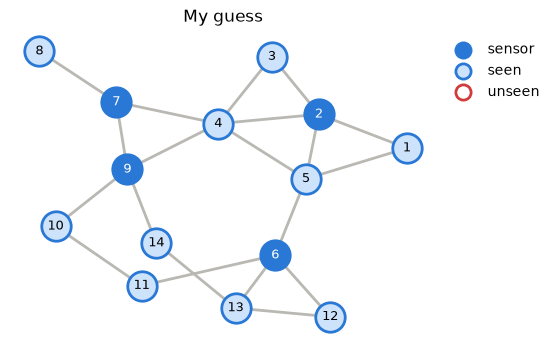

In [3]:
my_guess = [7, 2, 9, 6]          # edit this list of bus numbers
check_placement(grid, my_guess)
draw_grid(grid, my_guess, "My guess", pos=pos14)

## Milestone 2: classical baselines

- **Greedy (your TODO):** keep adding the sensor that sees the most still-unseen buses. Fast, but not always the fewest.
- **Integer program (provided):** an ILP (integer linear program) gives each bus a 0/1 variable $x_b$ and minimizes $\sum_b x_b$ so that every bus has at least one sensor among itself and its neighbors. `scipy.optimize.milp` solves it exactly.

Done when you have the optimal count and its runtime.

In [4]:
def greedy_placement(g):
    # Add sensors one at a time, always at the bus that sees the most unseen buses.
    chosen = []
    unseen = set(g["buses"])
    while unseen:
        b = max(g["buses"], key=lambda b: len(({b} | g["neighbors"][b]) & unseen))
        chosen.append(b)
        unseen -= {b} | g["neighbors"][b]
    return chosen

greedy: [2, 11] in 0.0 ms
IEEE 14-bus, 6-substation piece | rules: see neighbors | sensors at [2, 11]
  VALID with 2 sensors, redundancy 6
  if the sensor at any of [2, 11] fails, some bus goes unseen

ILP: [2, 11] in 20.4 ms
IEEE 14-bus, 6-substation piece | rules: see neighbors | sensors at [2, 11]
  VALID with 2 sensors, redundancy 6
  if the sensor at any of [2, 11] fails, some bus goes unseen

greedy: [4, 6, 9, 1, 7] in 0.0 ms
IEEE 14-bus | rules: see neighbors | sensors at [1, 4, 6, 7, 9]
  VALID with 5 sensors, redundancy 23
  if the sensor at any of [1, 4, 6, 7, 9] fails, some bus goes unseen

ILP: [2, 7, 11, 13] in 12.9 ms
IEEE 14-bus | rules: see neighbors | sensors at [2, 7, 11, 13]
  VALID with 4 sensors, redundancy 16
  if the sensor at any of [2, 7, 11, 13] fails, some bus goes unseen



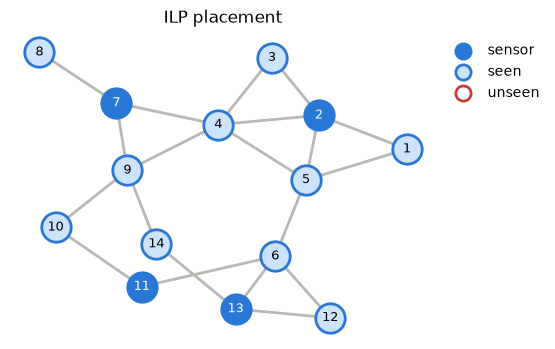

In [5]:
def ilp_placement(g, twice=False):
    # Exact minimum: one 0/1 variable per bus, and for every bus
    # (sensors on it or its neighbors) >= 1, or >= 2 with twice=True (N-1 stretch)
    buses = g["buses"]
    A = np.array([[1 if c == b or c in g["neighbors"][b] else 0 for c in buses] for b in buses])
    res = milp(c=np.ones(len(buses)), constraints=LinearConstraint(A, lb=2 if twice else 1),
               integrality=np.ones(len(buses)), bounds=Bounds(0, 1))
    return [b for b, x in zip(buses, res.x) if x > 0.5]


for g in [piece, grid]:
    for name, method in [("greedy", greedy_placement), ("ILP", ilp_placement)]:
        try:
            t0 = time.perf_counter()
            chosen = method(g)
            ms = 1000 * (time.perf_counter() - t0)
        except NotImplementedError:
            print(f"{name}: TODO\n")
            continue
        print(f"{name}: {chosen} in {ms:.1f} ms")
        check_placement(g, chosen)
        print()

draw_grid(grid, ilp_placement(grid), "ILP placement", pos=pos14)

## Milestone 3: the cost function

*First: one teammate works through `qaoa_primer.ipynb` (the 6-node part, about 45 minutes), ideally while others do milestones 1 and 2. Bring back one sentence on how its Max-Cut cost relates to the cost below.*

Give each bus one qubit: $x_b = 1$ means "put a sensor at bus $b$". QAOA will look for the bitstring with the lowest cost

$$C(x) = \underbrace{\sum_b x_b}_{\text{sensors}} \; + \; P \sum_b \underbrace{\prod_{j \in N[b]} (1 - x_j)}_{1 \text{ if bus } b \text{ is unseen}}$$

where $N[b]$ is bus $b$ plus its neighbors (its "group"). The product is 1 only when every bus in the group has no sensor, which is exactly when bus $b$ is unseen.

**Pick $P > 1$**, so an unseen bus costs more than one sensor. Then leaving a bus unseen always costs more than adding a sensor that sees it, so the cheapest bitstring is a valid placement with the fewest sensors. We use $P = 2$.

Why this form: it needs exactly one qubit per bus. The textbook QUBO (a cost with only pairs of 0/1 variables) turns each "at least one sensor" rule into an equation with extra slack qubits, about three times as many qubits for IEEE 14 (46 instead of 14).

**Bit order:** in this notebook a bitstring like `"010010"` lists qubit 0 first, so character `i` is bus `g["buses"][i]`. Qiskit prints qubit 0 *last*; the provided helpers handle the flip.

In [6]:
def bus_groups(g):
    # groups[i] = the qubits of bus i and its neighbors (qubit i is bus g["buses"][i])
    index = {b: i for i, b in enumerate(g["buses"])}
    return [sorted(index[c] for c in {b} | g["neighbors"][b]) for b in g["buses"]]


P = 2.0   # penalty per unseen bus, must be > 1

def placement_cost(bits, g, P=P):
    # C(x) = number of sensors + P * number of unseen buses. bits[i] is "0" or "1" for qubit i.
    x = [int(c) for c in bits]
    groups = bus_groups(g)
    sensors = sum(x)
    unseen = sum(1 for grp in groups if all(x[j] == 0 for j in grp))
    return sensors + P * unseen

In [7]:
def cost_table(g, P=P):
    # Cost of every bitstring, in the order of Qiskit's statevector: bit i of index z is qubit i.
    # format(z, "06b") puts qubit 0 last (Qiskit style), so [::-1] puts it first (our style).
    n = len(g["buses"])
    return np.array([placement_cost(format(z, f"0{n}b")[::-1], g, P) for z in range(2 ** n)])


costs6 = cost_table(piece)
z = int(np.argmin(costs6))
cheapest = bits_to_buses(piece, format(z, "06b")[::-1])
print("Cheapest bitstring by your cost function ->", cheapest, "| cost", costs6[z])
check_placement(piece, cheapest)
print("ILP answer:", ilp_placement(piece))

Cheapest bitstring by your cost function -> [2, 11] | cost 2.0
IEEE 14-bus, 6-substation piece | rules: see neighbors | sensors at [2, 11]
  VALID with 2 sensors, redundancy 6
  if the sensor at any of [2, 11] fails, some bus goes unseen
ILP answer: [2, 11]


## Milestone 4: QAOA

QAOA starts with every qubit in $|+\rangle$ (all placements at once) and repeats two layers `layers` times:
- **cost layer** (your TODO): multiply each bitstring $x$ by the phase $e^{-i\gamma C(x)}$
- **mixer layer** (provided): `rx(2*beta)` on every qubit

A classical optimizer tunes the angles $\gamma, \beta$ (provided). The cost layer has two kinds of terms:
1. **Sensor cost** $x_b$: a phase $e^{-i\gamma}$ when qubit $i$ is 1. That is `qc.p(-gamma, i)`.
2. **Unseen penalty** $P \prod_{j \in N[b]} (1 - x_j)$: a phase $e^{-i\gamma P}$ only when every qubit in the group is 0. A multi-controlled phase `mcp` fires only when all its qubits are 1, so flip the group with X gates, apply `mcp`, and flip back.

This keeps the circuit at one qubit per bus with no extra qubits.

In [8]:
def cost_layer(qc, g, gamma, P=P):
    # Apply exp(-i * gamma * C(x)) to every bitstring x.
    groups = bus_groups(g)
    for i in range(len(g["buses"])):
        qc.p(-gamma, i)                         # sensor cost
    for grp in groups:                          # unseen penalty
        qc.x(grp)
        qc.mcp(-gamma * P, grp[:-1], grp[-1])
        qc.x(grp)

def check_cost_layer(g, gamma=0.37):
    # Compare your circuit's phases with exp(-i * gamma * C) from placement_cost.
    n = len(g["buses"])
    qc = QuantumCircuit(n)
    qc.h(range(n))
    cost_layer(qc, g, gamma)
    qc.save_statevector()
    state = np.asarray(sim.run(transpile(qc, sim)).result().get_statevector())
    ratio = state / (np.exp(-1j * gamma * cost_table(g)) / np.sqrt(2 ** n))
    ok = np.allclose(ratio, ratio[0], atol=1e-6)   # equal up to one global phase
    print(g["name"], "| cost layer matches your cost function:", ok)
    return ok


check_cost_layer(piece)

IEEE 14-bus, 6-substation piece | cost layer matches your cost function: True


True

### The QAOA loop (provided)

`run_qaoa` tunes the angles on the exact statevector, which is fast for 14 qubits. **Be clear about this in your story:** to tune, it computes the cost of every placement (64 for the piece, 16,384 for 14 buses), so the classical side already knows the best answer before QAOA runs. What you measure here is how QAOA reshapes the odds of each answer, not a speedup; at scale you'd have to estimate the cost from shots instead.

Two knobs to try:
- `layers`: more layers usually help, but make a longer circuit.
- `alpha`: `alpha=1` is textbook QAOA (minimize the average cost). `alpha=0.25` minimizes the average of the cheapest 25% of outcomes (called CVaR), which rewards QAOA for its best answers and usually finds the optimum more often.

In [9]:
def qaoa_circuit(g, params, P=P, measure=False):
    # params = [gamma_1 .. gamma_L, beta_1 .. beta_L]
    L = len(params) // 2
    n = len(g["buses"])
    qc = QuantumCircuit(n, n) if measure else QuantumCircuit(n)
    qc.h(range(n))
    for gamma, beta in zip(params[:L], params[L:]):
        cost_layer(qc, g, gamma, P)
        qc.rx(2 * beta, range(n))          # mixer
    if measure:
        qc.measure(range(n), range(n))
    else:
        qc.save_statevector()
    return qc


def qaoa_probs(g, params, P=P):
    # Exact chance of every bitstring (index z: bit i of z is qubit i)
    state = sim.run(transpile(qaoa_circuit(g, params, P), sim)).result().get_statevector()
    return np.abs(np.asarray(state)) ** 2


def score(probs, costs, alpha):
    # Average cost over the cheapest `alpha` share of outcomes (alpha=1: plain average)
    order = np.argsort(costs)
    pr, c = probs[order], costs[order]
    take = np.clip(alpha - (np.cumsum(pr) - pr), 0, pr)
    return take @ c / alpha


def run_qaoa(g, layers=1, P=P, alpha=0.25, maxiter=100):
    costs = cost_table(g, P)
    objective = lambda params: score(qaoa_probs(g, params, P), costs, alpha)
    k = (np.arange(layers) + 0.5) / layers
    # a few "ramp" starts (gamma grows, beta shrinks, like a slow anneal); keep the best
    starts = [np.concatenate([k * a, (1 - k) * b]) for a, b in [(0.2, 0.2), (0.3, 0.6), (0.6, 0.3), (0.4, 0.4)]]
    x0 = min(starts, key=objective)
    result = minimize(objective, x0, method="COBYLA", options={"maxiter": maxiter, "rhobeg": 0.2})
    return result.x, qaoa_probs(g, result.x, P)


def outcome_shares(g, probs):
    # Split the probability into: optimal, valid with extra sensors, leaves a bus unseen
    n = len(g["buses"])
    z = np.arange(2 ** n)
    sensors = sum((z >> i) & 1 for i in range(n))
    unseen = sum((z & sum(1 << j for j in grp)) == 0 for grp in bus_groups(g))
    best, _ = brute_force_best(g)
    valid = unseen == 0
    return {"optimal": probs[valid & (sensors == best)].sum(),
            "valid, extra sensors": probs[valid & (sensors > best)].sum(),
            "leaves a bus unseen": probs[~valid].sum()}


def plot_outcomes(rows, title):
    colors = {"optimal": "#0ca30c", "valid, extra sensors": "#fab219", "leaves a bus unseen": "#d03b3b"}
    fig, ax = plt.subplots(figsize=(8, 0.6 * len(rows) + 1.2))
    labels = list(rows)[::-1]
    left = np.zeros(len(labels))
    for kind, color in colors.items():
        vals = np.array([rows[r][kind] for r in labels])
        ax.barh(labels, vals, left=left, color=color, edgecolor="white", linewidth=2, label=kind)
        for y, (l, v) in enumerate(zip(left, vals)):
            if v > 0.06:
                ax.text(l + v / 2, y, f"{v:.0%}", ha="center", va="center", fontsize=9)
        left += vals
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_xlabel("share of shots")
    ax.set_title(title, pad=26)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    plt.tight_layout()
    plt.show()
    for r, s in rows.items():
        print(f"{r:28s}" + "  ".join(f"{k}: {v:6.2%}" for k, v in s.items()))

In [10]:
layers6 = 1     # keep 1 for hardware: a short circuit
t0 = time.perf_counter()
params6, probs6 = run_qaoa(piece, layers=layers6)
print(f"6-piece: {time.perf_counter() - t0:.1f} s, angles {np.round(params6, 3)}")
for z in np.argsort(probs6)[::-1][:3]:   # QAOA's three most likely answers: not all of them are valid
    buses = bits_to_buses(piece, format(z, '06b')[::-1])
    r = check_placement(piece, buses, show=False)
    print(f"  {probs6[z]:.1%}  sensors at {buses}  ->  " + ("valid" if r["valid"] else f"NOT valid: buses {r['unseen']} unseen"))

6-piece: 3.2 s, angles [-1.571  0.5  ]
  21.1%  sensors at [2, 11]  ->  valid
  9.9%  sensors at [6, 11]  ->  NOT valid: buses [2, 3] unseen
  9.9%  sensors at [2, 5]  ->  NOT valid: buses [10, 11] unseen


In [11]:
layers14 = 5
t0 = time.perf_counter()
params14, probs14 = run_qaoa(grid, layers=layers14)
print(f"14 buses: {time.perf_counter() - t0:.1f} s, angles {np.round(params14, 3)}")
for z in np.argsort(probs14)[::-1][:3]:   # QAOA's three most likely answers: not all of them are valid
    buses = bits_to_buses(grid, format(z, '014b')[::-1])
    r = check_placement(grid, buses, show=False)
    print(f"  {probs14[z]:.1%}  sensors at {buses}  ->  " + ("valid" if r["valid"] else f"NOT valid: buses {r['unseen']} unseen"))

14 buses: 26.9 s, angles [-0.183 -0.58  -0.447  0.584  0.742  0.585  0.477  0.403 -0.054 -0.401]
  5.0%  sensors at [2, 6, 7, 9]  ->  valid
  4.3%  sensors at [2, 6, 8, 9]  ->  valid
  2.0%  sensors at [2, 7, 11, 13]  ->  valid


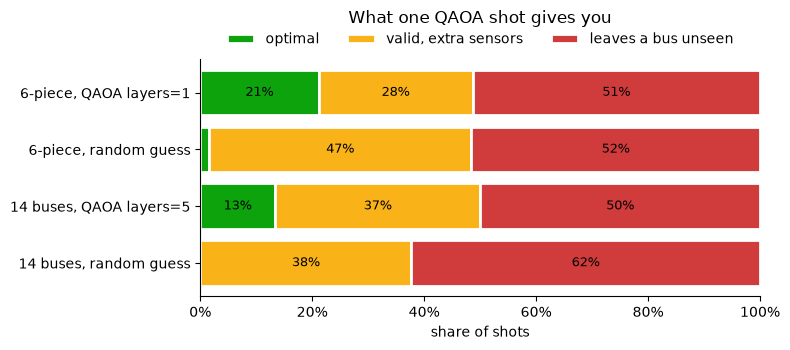

6-piece, QAOA layers=1      optimal: 21.14%  valid, extra sensors: 27.52%  leaves a bus unseen: 51.34%
6-piece, random guess       optimal:  1.56%  valid, extra sensors: 46.88%  leaves a bus unseen: 51.56%
14 buses, QAOA layers=5     optimal: 13.39%  valid, extra sensors: 36.66%  leaves a bus unseen: 49.95%
14 buses, random guess      optimal:  0.03%  valid, extra sensors: 37.70%  leaves a bus unseen: 62.27%


In [12]:
n6, n14 = len(piece["buses"]), len(grid["buses"])
plot_outcomes({
    f"6-piece, QAOA layers={layers6}": outcome_shares(piece, probs6),
    "6-piece, random guess": outcome_shares(piece, np.full(2 ** n6, 2.0 ** -n6)),
    f"14 buses, QAOA layers={layers14}": outcome_shares(grid, probs14),
    "14 buses, random guess": outcome_shares(grid, np.full(2 ** n14, 2.0 ** -n14)),
}, "What one QAOA shot gives you")

## Milestone 5: run the 6-substation piece on IonQ

1. Run the cell below as is. It sends your tuned 6-piece circuit to IonQ's **free** simulator with IonQ's gate-noise model for Forte (`forte-1`). Compare settings there (for example `layers6 = 1` vs `2`, or `alpha`) before you spend credits.
2. When you're happy, swap in the IonQ Forte QPU lines and run once at **200 shots or fewer**. Queues can take hours, so send it early.
3. Recommended, and free: run the same circuit on Quantinuum's H2 emulator too (the cell has the lines) and compare its noise with IonQ's. Before you switch devices, save the result you have (for example `counts_ionq_sim = counts`) so you can chart both.
4. Copy each job ID into your run record. If the queue is stuck, keep the job ID and your noisy-simulator result to show the judges, and ask a qBraid mentor about a backup device.

In [13]:
# Your tuned 6-piece circuit, written in basic gates so the two-qubit count is the real one
qc = transpile(qaoa_circuit(piece, params6, measure=True), basis_gates=["rz", "sx", "x", "cx"])
print("Qubits:", qc.num_qubits, "| two-qubit (CX) gates:", qc.count_ops()["cx"], "(IonQ advises a few dozen at most)")
# qBraid may warn that measurements are ignored: IonQ always measures every qubit, so that's fine

# --- Run on a quantum computer through qBraid ---
from qbraid.runtime import QbraidProvider
import warnings
warnings.filterwarnings("ignore", message="Circuit contains measurement gates")  # IonQ measures every qubit anyway

provider = QbraidProvider()   # in qBraid Lab this uses your account automatically

# 1) Practice for free: IonQ's simulator with a realistic noise model
device = provider.get_device("ionq:ionq:sim:simulator")
job = device.run(qc, shots=200, runtime_options={"noise_model": "forte-1"})

# 2) Your real hardware run (uses credits). Swap in the QPU when you're ready:
# device = provider.get_device("ionq:ionq:qpu:forte-1")    # or "aws:ionq:qpu:forte-1" if this one shows as unavailable
# job = device.run(qc, shots=200)

# 3) Also free: Quantinuum's H2 emulator. It models a real trapped-ion computer's noise, readout
#    error included. Accept Quantinuum's terms once first (Devices > Quantinuum in your qBraid account).
#    It's an emulator: label its results that way, not as hardware.
# device = provider.get_device("quantinuum:quantinuum:sim:h2-emulator")
# job = device.run(qc, shots=200)

print("Device:", device.id, "| Job ID:", job.id)   # copy both into your run record
counts = job.result().data.get_counts()
print("Most common results:", dict(sorted(counts.items(), key=lambda kv: -kv[1])[:5]))

Qubits: 6 | two-qubit (CX) gates: 26 (IonQ advises a few dozen at most)
Device: ionq:ionq:sim:simulator | Job ID: ionq:ionq:sim:simulator-0add-qjob-6af8d970c8f5265fb3f20b62
Most common results: {'100001': 44, '000101': 17, '101000': 13, '000110': 12, '011000': 9}


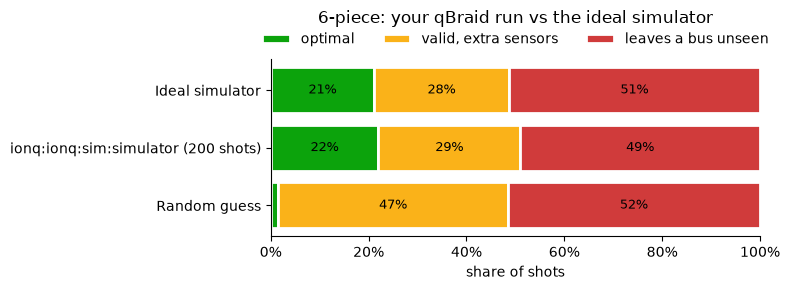

Ideal simulator             optimal: 21.14%  valid, extra sensors: 27.52%  leaves a bus unseen: 51.34%
ionq:ionq:sim:simulator (200 shots)optimal: 22.00%  valid, extra sensors: 29.00%  leaves a bus unseen: 49.00%
Random guess                optimal:  1.56%  valid, extra sensors: 46.88%  leaves a bus unseen: 51.56%
Most common answer in your qBraid run: sensors at [2, 11]


In [14]:
probs_hw = np.zeros(2 ** n6)
for key, c in counts.items():
    probs_hw[int(key.replace(" ", ""), 2)] += c   # int(key, 2) reads Qiskit's order: bit i is qubit i
probs_hw /= probs_hw.sum()

plot_outcomes({
    "Ideal simulator": outcome_shares(piece, probs6),
    f"{device.id} ({sum(counts.values())} shots)": outcome_shares(piece, probs_hw),
    "Random guess": outcome_shares(piece, np.full(2 ** n6, 2.0 ** -n6)),
}, "6-piece: your qBraid run vs the ideal simulator")
top = max(counts, key=counts.get)
print("Most common answer in your qBraid run: sensors at", bits_to_buses(piece, top.replace(" ", "")[::-1]))

## Stretch ideas

- **Zero-injection buses:** `check_placement(grid, chosen, zib=True)` applies the rule (IEEE 14 bus 7 has no load and no generator). How many sensors can you save?
- **N-1:** `check_placement(grid, chosen, n1=True)` and `ilp_placement(grid, twice=True)`. For QAOA, penalize each missing sighting: P × (2 − sightings) for a bus seen fewer than twice, with P > 1. (A flat penalty for "seen only once" doesn't work: with P = 2 it makes invalid placements tie for best.)
- **Critical buses:** a bigger penalty alone won't change the best placement when every bus can be covered (every best answer already sees every bus). Use the weights with a fixed budget (k sensors: maximize the weighted buses seen), or require critical buses to be seen twice. For weights, try buses with big loads in `grid["load_mw"]`.
- **30 buses:** load `data/ieee30.json`. The exact cost table no longer fits in memory, so switch to sampled shots and qBraid's GPU simulator.

## What to have ready for the judges

| Milestone | Be ready to show |
|---|---|
| 1. Understand it | your hand placement and one sentence on what a PMU sees |
| 2. Classical baseline | greedy and ILP placements, their sensor counts and runtimes, and what happens if each sensor in your chosen placement fails (which buses go unseen) |
| 3. Cost function | your `placement_cost`, and the check showing its cheapest answer matches the ILP on the 6-piece, plus one sentence on how the primer's Max-Cut cost relates to yours |
| 4. QAOA | the outcome chart for the 6-piece and 14 buses, with your `layers`, `P` and `alpha` |
| 5. IonQ run | your run record (device, job ID, shots, status), the CX count, and the chart, labeled simulator, emulator or QPU |
| 6. Tell the story | your five slides (see the main README): the customer and what PMUs cost them, your placement and what it sees, what happens if one fails, classical vs quantum, and what you learned. Rehearse in the time the organizers give you |

Understanding and clarity count more than code. This notebook is a starter: add your own cells, notebooks and tools, and expand as far as you like. If something failed or you couldn't find a solution, say so clearly and explain why.

Due Sunday 9:00 AM: your pitch deck and your code as a ZIP. See "What to submit" in the main README for where.